# **EDA & Cleaning** 

### **Step 1: Load and inspect**

In [2]:
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt 
import seaborn as sns 

df = pd.read_csv("../data/hotel_bookings.csv")


In [ ]:
# We use .shape() to find the dimensions (cloumns) and the size of the dataset (Rows)
print(df.shape) 

# Use head() to quickly inspect the first few rows  
df.head()

(119390, 32)


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,...,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,...,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03


In [ ]:

# Use .info() to get a quick, concise structural health check of the dataframe 
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 119390 entries, 0 to 119389
Data columns (total 32 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   hotel                           119390 non-null  str    
 1   is_canceled                     119390 non-null  int64  
 2   lead_time                       119390 non-null  int64  
 3   arrival_date_year               119390 non-null  int64  
 4   arrival_date_month              119390 non-null  str    
 5   arrival_date_week_number        119390 non-null  int64  
 6   arrival_date_day_of_month       119390 non-null  int64  
 7   stays_in_weekend_nights         119390 non-null  int64  
 8   stays_in_week_nights            119390 non-null  int64  
 9   adults                          119390 non-null  int64  
 10  children                        119386 non-null  float64
 11  babies                          119390 non-null  int64  
 12  meal                       

In [ ]:
# Use .describe() to get a comprehensive statistical summary of the datasets's distribution 
df.describe()

,is_canceled,lead_time,arrival_date_year,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,booking_changes,agent,company,days_in_waiting_list,adr,required_car_parking_spaces,total_of_special_requests
count,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119386.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,103050.000000,6797.000000,119390.000000,119390.000000,119390.000000,119390.000000
mean,0.370416,104.011416,2016.156554,27.165173,15.798241,0.927599,2.500302,1.856403,0.103890,0.007949,0.031912,0.087118,0.137097,0.221124,86.693382,189.266735,2.321149,101.831122,0.062518,0.571363
std,0.482918,106.863097,0.707476,13.605138,8.780829,0.998613,1.908286,0.579261,0.398561,0.097436,0.175767,0.844336,1.497437,0.652306,110.774548,131.655015,17.594721,50.535790,0.245291,0.792798
min,0.000000,0.000000,2015.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,6.000000,0.000000,-6.380000,0.000000,0.000000
25%,0.000000,18.000000,2016.000000,16.000000,8.000000,0.000000,1.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,9.000000,62.000000,0.000000,69.290000,0.000000,0.000000
50%,0.000000,69.000000,2016.000000,28.000000,16.000000,1.000000,2.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,14.000000,179.000000,0.000000,94.575000,0.000000,0.000000
75%,1.000000,160.000000,2017.000000,38.000000,23.000000,2.000000,3.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,229.000000,270.000000,0.000000,126.000000,0.000000,1.000000
max,1.000000,737.000000,2017.000000,53.000000,31.000000,19.000000,50.000000,55.000000,10.000000,10.000000,1.000000,26.000000,72.000000,21.000000,535.000000,543.000000,391.000000,5400.000000,8.000000,5.000000


In [12]:
df['adr'].describe()

count    119390.000000
mean        101.831122
std          50.535790
min          -6.380000
25%          69.290000
50%          94.575000
75%         126.000000
max        5400.000000
Name: adr, dtype: float64

#### *Missing Values*

In [14]:
df.isna().sum()

hotel                                  0
is_canceled                            0
lead_time                              0
arrival_date_year                      0
arrival_date_month                     0
arrival_date_week_number               0
arrival_date_day_of_month              0
stays_in_weekend_nights                0
stays_in_week_nights                   0
adults                                 0
children                               4
babies                                 0
meal                                   0
country                              488
market_segment                         0
distribution_channel                   0
is_repeated_guest                      0
previous_cancellations                 0
previous_bookings_not_canceled         0
reserved_room_type                     0
assigned_room_type                     0
booking_changes                        0
deposit_type                           0
agent                              16340
company         

#### *Duplicates*

In [16]:
print(df.duplicated().sum())

31994


In [32]:
print( df["deposit_type"].value_counts())
print("\n",df["is_canceled"].value_counts(normalize=True))
print("\n",df["country"].value_counts().head(10))
print("\n",df["agent"].value_counts(dropna=False))
print("\n",df["hotel"].value_counts(normalize=True)* 100)


deposit_type
No Deposit    104641
Non Refund     14587
Refundable       162
Name: count, dtype: int64

 is_canceled
0    0.629584
1    0.370416
Name: proportion, dtype: float64

 country
PRT    48590
GBR    12129
FRA    10415
ESP     8568
DEU     7287
ITA     3766
IRL     3375
BEL     2342
BRA     2224
NLD     2104
Name: count, dtype: int64

 agent
9.0      31961
NaN      16340
240.0    13922
1.0       7191
14.0      3640
         ...  
444.0        1
408.0        1
388.0        1
453.0        1
480.0        1
Name: count, Length: 334, dtype: int64

 hotel
City Hotel      66.446101
Resort Hotel    33.553899
Name: proportion, dtype: float64


In [9]:
df["meal"].value_counts(normalize=True) * 100

meal
BB           77.318033
HB           12.114080
SC            8.920345
Undefined     0.979144
FB            0.668398
Name: proportion, dtype: float64

In [35]:
df.groupby("deposit_type")["is_canceled"].mean()

deposit_type
No Deposit    0.283770
Non Refund    0.993624
Refundable    0.222222
Name: is_canceled, dtype: float64

In [38]:
df[df["deposit_type"] == "Non Refund"]["market_segment"].value_counts()


market_segment
Groups           9172
Offline TA/TO    5006
Corporate         334
Online TA          56
Direct             19
Name: count, dtype: int64

In [43]:
# Do Groups cancel more even WITHOUT a non-refund deposit?
df[df["deposit_type"] == "No Deposit"].groupby("market_segment")["is_canceled"].mean()



market_segment
Aviation         0.219409
Complementary    0.130552
Corporate        0.136978
Direct           0.152293
Groups           0.282996
Offline TA/TO    0.172107
Online TA        0.366434
Undefined        1.000000
Name: is_canceled, dtype: float64

In [42]:
# Does PRT cancel more WITHOUT a non-refund deposit?
df[df["deposit_type"] == "No Deposit"].groupby(df["country"] == "PRT")["is_canceled"].mean()

country
False    0.232487
True     0.388640
Name: is_canceled, dtype: float64

**Findings:**
- Find missing values in the childern, country, agent and company coloumns 
- Find 31994 duplicates rows in the dataset 
- Find that canceled bookings are 99 percent of non-refund bookings 
- The adr coloum has a negative values and large maximum value 
- The adult coloum has 0 for the minimum value which means some rows having 0 adults 
- The total nights coloum has 0 for the minimum value , which also mean some rows are having 0 nights 
- 

### **Step 2: EDA**

In [11]:
month_order = ["January", "February", "March", "April", "May", "June", "July", "August", "September", "October", "November", "December"]

def cancel_rate(df, col, order=None):
    """ Bar chart of cancellation rate per category, with counts printed."""
    g = df.groupby(col)["is_canceled"].agg(rate="mean", n="size")
    if order: g= g.reindex(order)
    print(g)
    g["rate"].plot(kind="bar", figsize=(8,4))
    plt.ylabel("cancellation rate"); plt.title(f"Cancellation rate by {col}")
    plt.show()

                        rate      n
arrival_date_month                 
January             0.304773   5929
February            0.334160   8068
March               0.321523   9794
April               0.407972  11089
May                 0.396658  11791
June                0.414572  10939
July                0.374536  12661
August              0.377531  13877
September           0.391702  10508
October             0.380466  11160
November            0.312334   6794
December            0.349705   6780


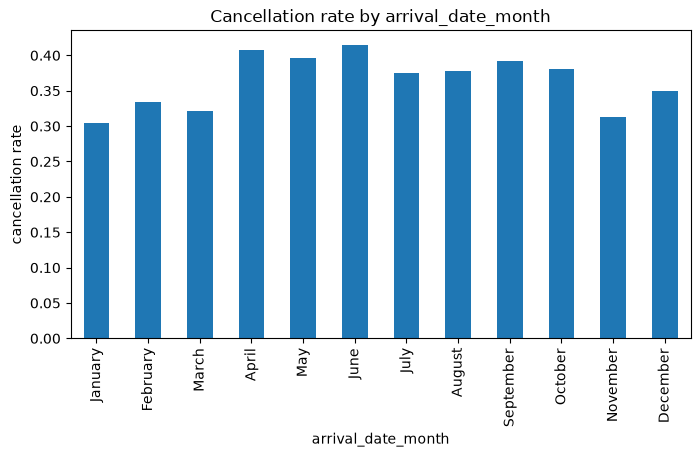

                  rate      n
hotel                        
City Hotel    0.417270  79330
Resort Hotel  0.277634  40060


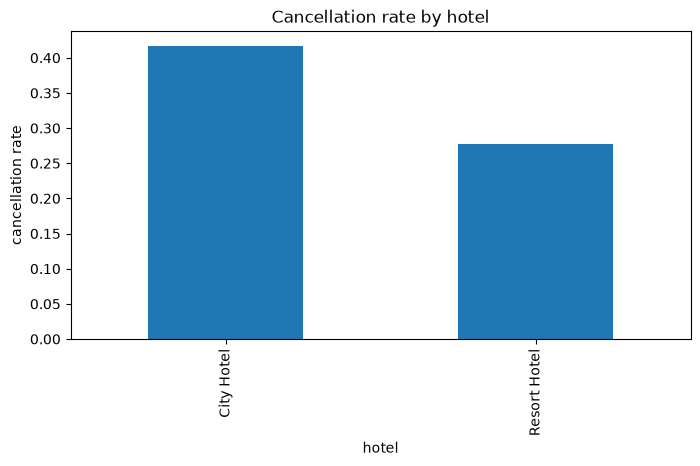

                  rate       n
deposit_type                  
No Deposit    0.283770  104641
Non Refund    0.993624   14587
Refundable    0.222222     162


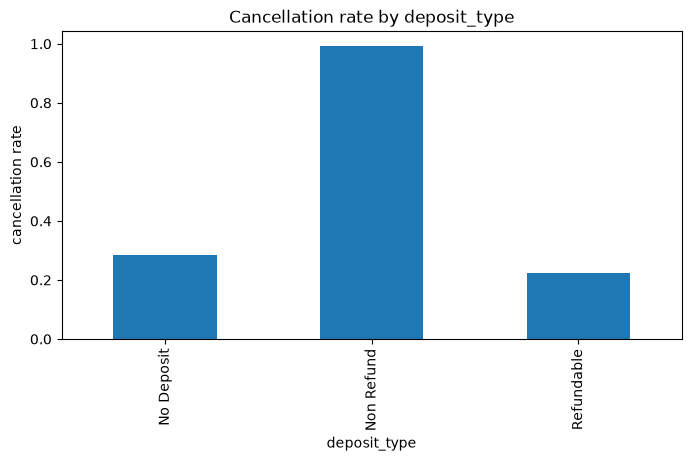

                    rate      n
market_segment                 
Aviation        0.219409    237
Complementary   0.130552    743
Corporate       0.187347   5295
Direct          0.153419  12606
Groups          0.610620  19811
Offline TA/TO   0.343160  24219
Online TA       0.367211  56477
Undefined       1.000000      2


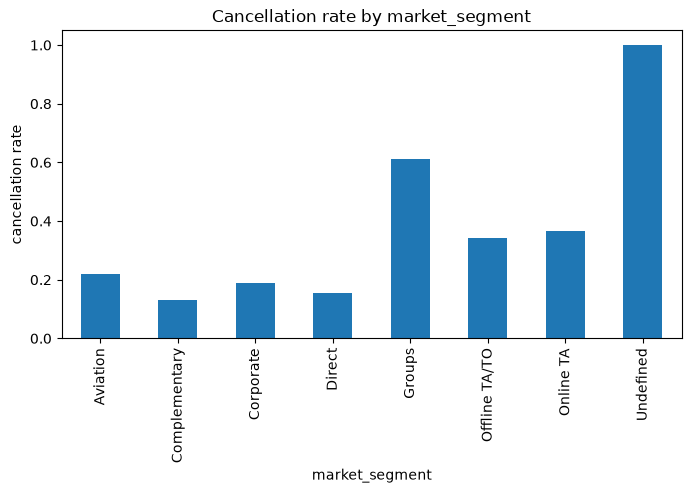

In [14]:
cancel_rate(df, "arrival_date_month", order=month_order)
cancel_rate(df, "hotel")
cancel_rate(df, "deposit_type")
cancel_rate(df, "market_segment")


                 rate      n
lead_bucket                 
0-7          0.096323  19746
8-30         0.278639  18960
31-90        0.376984  29553
91-180       0.447105  26439
181-365      0.554540  21544
365+         0.676620   3148


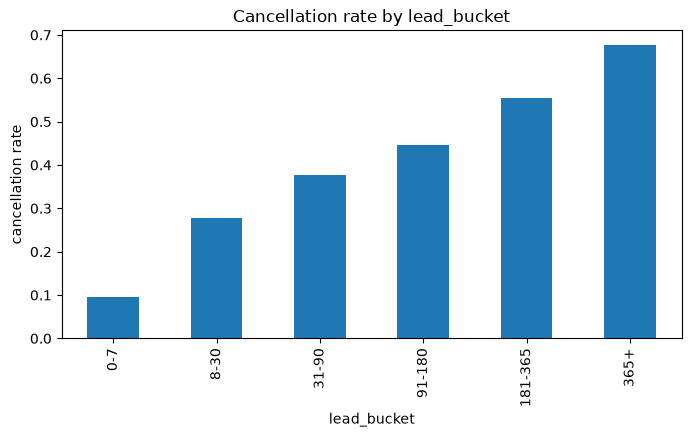

In [16]:
df["lead_bucket"] = pd.cut(df["lead_time"],
                           bins=[-1, 7, 30, 90, 180, 365, np.inf],
                           labels=["0-7","8-30","31-90","91-180","181-365","365+"])

cancel_rate(df, "lead_bucket")

In [17]:
df[df["deposit_type"]=="No Deposit"].groupby("lead_bucket")["is_canceled"].mean()

lead_bucket
0-7        0.091646
8-30       0.260440
31-90      0.321898
91-180     0.348607
181-365    0.398240
365+       0.206250
Name: is_canceled, dtype: float64

<Axes: xlabel='adr', ylabel='Count'>

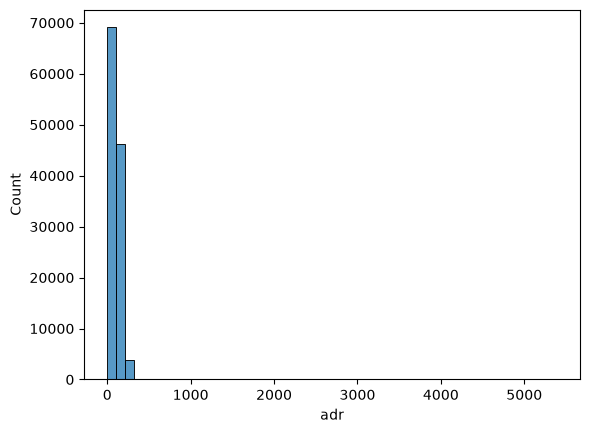

In [18]:
sns.histplot(df["adr"], bins=50)

<Axes: xlabel='adr', ylabel='Count'>

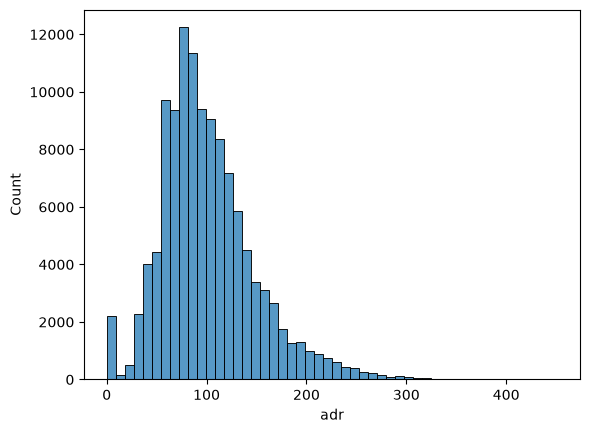

In [3]:
df = df[(df["adr"] >= 0) & (df["adr"] < 500)]   # threshold: check quantiles first
sns.histplot(df["adr"], bins=50)

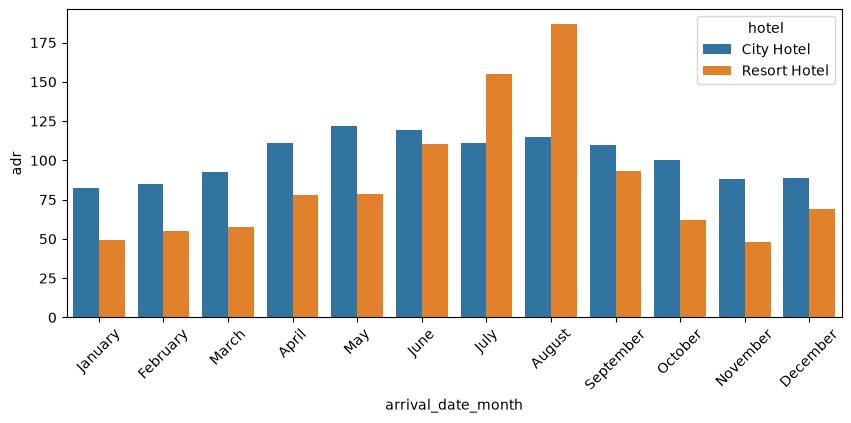

In [22]:
adr_by_month = (df.groupby(["arrival_date_month", "hotel"])["adr"]
                  .mean()
                  .reset_index())          # turns the index back into columns

plt.figure(figsize=(10,4))
sns.barplot(data=adr_by_month, x="arrival_date_month", y="adr",
            hue="hotel", order=month_order)
plt.xticks(rotation=45)
plt.show()

is_canceled                       1.000000
lead_time                         0.293131
total_of_special_requests         0.234669
required_car_parking_spaces       0.195489
booking_changes                   0.144388
previous_cancellations            0.110134
is_repeated_guest                 0.084745
agent                             0.083091
adults                            0.060010
previous_bookings_not_canceled    0.057347
days_in_waiting_list              0.054186
adr                               0.048833
babies                            0.032492
stays_in_week_nights              0.024776
company                           0.020642
arrival_date_year                 0.016668
arrival_date_week_number          0.008149
arrival_date_day_of_month         0.006155
children                          0.005046
stays_in_weekend_nights           0.001773
Name: is_canceled, dtype: float64

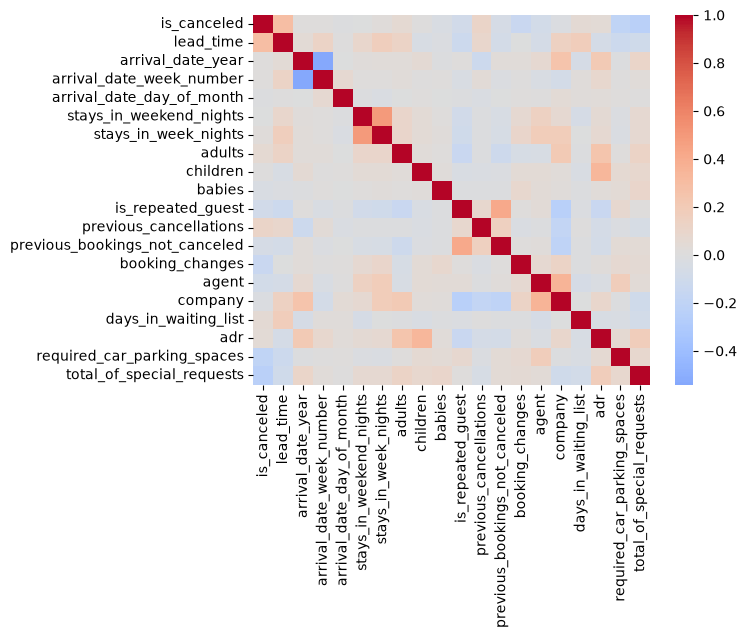

In [4]:
corr = df.select_dtypes("number").corr()

sns.heatmap(corr, cmap="coolwarm", center=0)
corr["is_canceled"].abs().sort_values(ascending=False)

In [24]:
df["is_canceled"].value_counts(normalize=True)

is_canceled
0    0.629584
1    0.370416
Name: proportion, dtype: float64

### **Step 3: Cleaning**
